In [1440]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#inspect each one's shape, column data types, and null counts.
movies = pd.read_csv("dataset/movies.csv")
movie_keywords = pd.read_csv("dataset/movie_keywords.csv")
movie_genres = pd.read_csv("dataset/movie_genres.csv")
cast = pd.read_csv("dataset/cast.csv")
crew = pd.read_csv("dataset/crew.csv")
genres = pd.read_csv("dataset/genres.csv")

df_list = [
    movies,
    movie_keywords,
    movie_genres,
    cast,
    crew,
    genres
]

# Cleaning Movies

In [1442]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2509 entries, 0 to 2508
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movie_id           2509 non-null   int64  
 1   title              2509 non-null   object 
 2   original_language  2509 non-null   object 
 3   release_date       2509 non-null   object 
 4   runtime            2509 non-null   int64  
 5   budget             2509 non-null   float64
 6   revenue            2509 non-null   float64
 7   popularity         2509 non-null   float64
 8   vote_average       2509 non-null   float64
 9   vote_count         2509 non-null   int64  
 10  status             2509 non-null   object 
 11  overview           2509 non-null   object 
dtypes: float64(4), int64(3), object(5)
memory usage: 235.3+ KB


1. No null values (GOOD)
2. Data types of title,original_language,and overview is object. Should be string. Will be handled below.
3. relese_date should be in date data type

In [1443]:
movies.describe(include="object")

,title,original_language,release_date,status,overview
count,2509,2509,2509,2509,2509
unique,2452,21,2123,1,2499
top,Halloween,en,2017-12-22,Released,"After the death of Emperor Marcus Aurelius, hi..."
freq,3,2369,4,2509,2


There are some duplicates. Note specially about Title, overview. If both are same it could denote existence of same row.

All movies are released.

In [1444]:
movies[movies.duplicated(subset=["movie_id"],keep=False)].sort_values(by="movie_id")

,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview
56,98,Gladiator,en,2000-05-04,155,103000000.0,465516248.0,38.9610,8.230,21184,Released,"After the death of Emperor Marcus Aurelius, hi..."
2504,98,Gladiator,en,2000-05-04,155,103000000.0,465516248.0,38.9610,8.230,21184,Released,"After the death of Emperor Marcus Aurelius, hi..."
2501,414,Batman Forever,en,1995-06-16,121,100000000.0,336529144.0,10.8455,5.459,5660,Released,Batman faces off against two foes: the schizop...
902,414,Batman Forever,en,1995-06-16,121,100000000.0,336529144.0,10.8455,5.459,5660,Released,Batman faces off against two foes: the schizop...
2240,8814,Doom,en,2005-10-20,105,60000000.0,58100000.0,6.3758,5.202,2493,Released,A team of space marines known as the Rapid Res...
2502,8814,Doom,en,2005-10-20,105,60000000.0,58100000.0,6.3758,5.202,2493,Released,A team of space marines known as the Rapid Res...
2503,72570,The Vow,en,2012-02-05,104,30000000.0,196114570.0,9.7433,7.225,4287,Released,"Happy young married couple Paige and Leo are, ..."
1285,72570,The Vow,en,2012-02-05,104,30000000.0,196114570.0,9.7433,7.225,4287,Released,"Happy young married couple Paige and Leo are, ..."
2319,329833,Zoolander 2,en,2016-02-06,100,50000000.0,56722693.0,6.4048,4.927,2411,Released,Derek and Hansel are modelling again when an o...
2499,329833,Zoolander 2,en,2016-02-06,100,50000000.0,56722693.0,6.4048,4.927,2411,Released,Derek and Hansel are modelling again when an o...


In [1445]:
movies.drop_duplicates(inplace=True)

In [1446]:
movies[movies.duplicated()]

,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview


In [1447]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2503 entries, 0 to 2508
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movie_id           2503 non-null   int64  
 1   title              2503 non-null   object 
 2   original_language  2503 non-null   object 
 3   release_date       2503 non-null   object 
 4   runtime            2503 non-null   int64  
 5   budget             2503 non-null   float64
 6   revenue            2503 non-null   float64
 7   popularity         2503 non-null   float64
 8   vote_average       2503 non-null   float64
 9   vote_count         2503 non-null   int64  
 10  status             2503 non-null   object 
 11  overview           2503 non-null   object 
dtypes: float64(4), int64(3), object(5)
memory usage: 254.2+ KB


In [1448]:
movies.describe(include="object")

,title,original_language,release_date,status,overview
count,2503,2503,2503,2503,2503
unique,2452,21,2123,1,2499
top,Robin Hood,en,2014-10-01,Released,Young teenager Sam Witwicky becomes involved i...
freq,3,2363,4,2503,2


There are still some same titles, overview, but each denotes a different release and not exactly same. So each denotes a new movie.

In [1449]:
movies["release_date"]

0       2014-11-05
1       2010-07-15
2       2012-04-25
3       2008-07-16
4       2009-12-16
           ...    
2498    2010-01-06
2505    1995-04-08
2506    1987-06-27
2507    2000-01-28
2508    2011-03-08
Name: release_date, Length: 2503, dtype: object

In [1450]:
movies["release_date"] = pd.to_datetime(movies["release_date"].str.strip())

In [1451]:
movies.sample(6)

,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview
2342,68727,Trance,en,2013-03-27,101,20000000.0,2.430000e+07,3.7416,6.616,2383,Released,A violent gang enlists the help of a hypnother...
1053,631843,Old,en,2021-07-21,108,18000000.0,9.014651e+07,10.9424,6.323,4963,Released,A group of families on a tropical holiday disc...
329,495764,Birds of Prey (and the Fantabulous Emancipatio...,en,2020-02-05,109,75000000.0,2.055379e+08,11.9801,6.868,10903,Released,"Harley Quinn joins forces with a singer, an as..."
997,267860,London Has Fallen,en,2016-03-02,99,60000000.0,2.057544e+08,8.8877,6.225,5158,Released,"In London for the Prime Minister's funeral, Mi..."
1707,1226863,The Super Mario Galaxy Movie,en,2026-04-01,98,110000000.0,1.011157e+09,97.1210,8.261,3343,Released,Having thwarted Bowser's previous plot to marr...
80,281957,The Revenant,en,2015-12-25,157,135000000.0,5.329505e+08,19.0172,7.541,19513,Released,"In the 1820s, a frontiersman, Hugh Glass, sets..."


In [1452]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2503 entries, 0 to 2508
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   movie_id           2503 non-null   int64         
 1   title              2503 non-null   object        
 2   original_language  2503 non-null   object        
 3   release_date       2503 non-null   datetime64[ns]
 4   runtime            2503 non-null   int64         
 5   budget             2503 non-null   float64       
 6   revenue            2503 non-null   float64       
 7   popularity         2503 non-null   float64       
 8   vote_average       2503 non-null   float64       
 9   vote_count         2503 non-null   int64         
 10  status             2503 non-null   object        
 11  overview           2503 non-null   object        
dtypes: datetime64[ns](1), float64(4), int64(3), object(4)
memory usage: 254.2+ KB


In [1453]:
obj_cols = movies.select_dtypes("object").columns
for x in obj_cols:
    movies[f"{x}_new"] = movies[f"{x}"].str.strip().convert_dtypes(convert_string=True)

In [1454]:
obj_cols = movies.select_dtypes("object").columns
for x in obj_cols:
    print(movies[~(movies[f"{x}_new"] == movies[f"{x}"])])

Empty DataFrame
Columns: [movie_id, title, original_language, release_date, runtime, budget, revenue, popularity, vote_average, vote_count, status, overview, title_new, original_language_new, status_new, overview_new]
Index: []
Empty DataFrame
Columns: [movie_id, title, original_language, release_date, runtime, budget, revenue, popularity, vote_average, vote_count, status, overview, title_new, original_language_new, status_new, overview_new]
Index: []
Empty DataFrame
Columns: [movie_id, title, original_language, release_date, runtime, budget, revenue, popularity, vote_average, vote_count, status, overview, title_new, original_language_new, status_new, overview_new]
Index: []
Empty DataFrame
Columns: [movie_id, title, original_language, release_date, runtime, budget, revenue, popularity, vote_average, vote_count, status, overview, title_new, original_language_new, status_new, overview_new]
Index: []


In [1455]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2503 entries, 0 to 2508
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   movie_id               2503 non-null   int64         
 1   title                  2503 non-null   object        
 2   original_language      2503 non-null   object        
 3   release_date           2503 non-null   datetime64[ns]
 4   runtime                2503 non-null   int64         
 5   budget                 2503 non-null   float64       
 6   revenue                2503 non-null   float64       
 7   popularity             2503 non-null   float64       
 8   vote_average           2503 non-null   float64       
 9   vote_count             2503 non-null   int64         
 10  status                 2503 non-null   object        
 11  overview               2503 non-null   object        
 12  title_new              2503 non-null   string        
 13  original

1. Converted all object columns in string data type.
2. Made sure that there are no leading or trailing spaces or any escape characters

In [1456]:
movies=movies.drop(["title","original_language","status","overview"],axis=1)

In [1457]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2503 entries, 0 to 2508
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   movie_id               2503 non-null   int64         
 1   release_date           2503 non-null   datetime64[ns]
 2   runtime                2503 non-null   int64         
 3   budget                 2503 non-null   float64       
 4   revenue                2503 non-null   float64       
 5   popularity             2503 non-null   float64       
 6   vote_average           2503 non-null   float64       
 7   vote_count             2503 non-null   int64         
 8   title_new              2503 non-null   string        
 9   original_language_new  2503 non-null   string        
 10  status_new             2503 non-null   string        
 11  overview_new           2503 non-null   string        
dtypes: datetime64[ns](1), float64(4), int64(3), string(4)
memory usage:

Now moving towards numerical cols

NOTE - No null values are there in any feature of the data set.

In [1458]:
#runtime
movies[(movies["runtime"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new


No unexpected value is discoverd. Feature is OK!

In [1459]:
#budget
movies[(movies["budget"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new
403,664413,2020-02-07,114,0.0,9458590.0,10.2110,6.992,9564,365 Days,pl,Released,"A woman falls victim to a dominant mafia boss,..."
468,466282,2018-08-17,100,0.0,0.0,8.0968,7.594,8744,To All the Boys I've Loved Before,en,Released,Lara Jean's love life goes from imaginary to o...
598,454983,2018-05-11,105,0.0,0.0,8.4785,7.160,7494,The Kissing Booth,en,Released,When teenager Elle's first kiss leads to a for...
754,200727,2014-10-16,102,0.0,4439431.0,9.0550,7.814,6534,"Love, Rosie",en,Released,"Since the moment they met at age 5, Rosie and ..."
891,559969,2019-10-11,123,0.0,0.0,9.8869,7.047,5735,El Camino: A Breaking Bad Movie,en,Released,In the wake of his dramatic escape from captiv...
...,...,...,...,...,...,...,...,...,...,...,...,...
2447,198375,2013-05-31,46,0.0,820165.0,5.1660,7.592,2264,The Garden of Words,ja,Released,"Takao, who is training to become a shoemaker, ..."
2448,339692,2017-07-07,121,0.0,0.0,8.8099,6.965,2263,Shot Caller,en,Released,A newly-released prison gangster is forced by ...
2459,23488,2009-09-09,112,0.0,4706919.0,5.9445,6.048,2256,Dorian Gray,en,Released,Seduced into the decadent world of Lord Henry ...
2471,73861,2010-01-06,104,0.0,0.0,18.9190,5.453,2242,A Serbian Film,sr,Released,Retired porn star Milos leads a normal family ...


NOTE - There  are 90 rows with 0 values in budget col. Replace them with NaN to be investigated later.

In [1460]:
#revenue
movies[(movies["revenue"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new
324,791373,2021-03-18,242,70000000.0,0.0,19.7621,8.083,10986,Zack Snyder's Justice League,en,Released,Determined to ensure Superman's ultimate sacri...
340,405774,2018-12-13,124,19800000.0,0.0,12.4047,6.825,10704,Bird Box,en,Released,Five years after an ominous unseen presence dr...
468,466282,2018-08-17,100,0.0,0.0,8.0968,7.594,8744,To All the Boys I've Loved Before,en,Released,Lara Jean's love life goes from imaginary to o...
554,766507,2022-08-02,100,65000000.0,0.0,18.9762,7.655,7864,Prey,en,Released,"When danger threatens her camp, the fierce and..."
598,454983,2018-05-11,105,0.0,0.0,8.4785,7.160,7494,The Kissing Booth,en,Released,When teenager Elle's first kiss leads to a for...
...,...,...,...,...,...,...,...,...,...,...,...,...
2469,755566,2022-08-05,114,100000000.0,0.0,10.6059,6.734,2244,Day Shift,en,Released,An LA vampire hunter has a week to come up wit...
2471,73861,2010-01-06,104,0.0,0.0,18.9190,5.453,2242,A Serbian Film,sr,Released,Retired porn star Milos leads a normal family ...
2480,11104,1994-07-14,103,160000.0,0.0,11.6298,7.974,2237,Chungking Express,cn,Released,Two melancholic Hong Kong policemen fall in lo...
2481,500840,2020-08-28,135,0.0,0.0,5.1510,6.535,2236,I'm Thinking of Ending Things,en,Released,Nothing is as it seems when a woman experienci...


NOTE - There  are 102 rows with 0 values in revenue col. Replace them with NaN to be investigated later.

In [1461]:
#popularity
movies[(movies["popularity"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new


No unexpected value encountered. Feature OK!

In [1462]:
#vote_Avg
movies[(movies["vote_average"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new


No unexpected value encountered. Feature OK!

In [1463]:
#vote_count
movies[(movies["vote_count"] <= 0)]

,movie_id,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,title_new,original_language_new,status_new,overview_new


No unexpected value encountered. Feature OK!

Handling 0's in budget and revenue

In [1464]:
print("Pct Missing in budget",(movies[(movies["budget"] <= 0)].shape[0]/movies.shape[0]) *100)
print("Pct Missing in revenue",(movies[(movies["revenue"] <= 0)].shape[0]/movies.shape[0]) *100)

Pct Missing in budget 3.595685177786656
Pct Missing in revenue 4.0751098681582105


In [1465]:
movies["budget_new"] = movies["budget"].replace(0,np.nan)
movies["revenue_new"] = movies["revenue"].replace(0,np.nan)

<Axes: xlabel='revenue_new', ylabel='Density'>

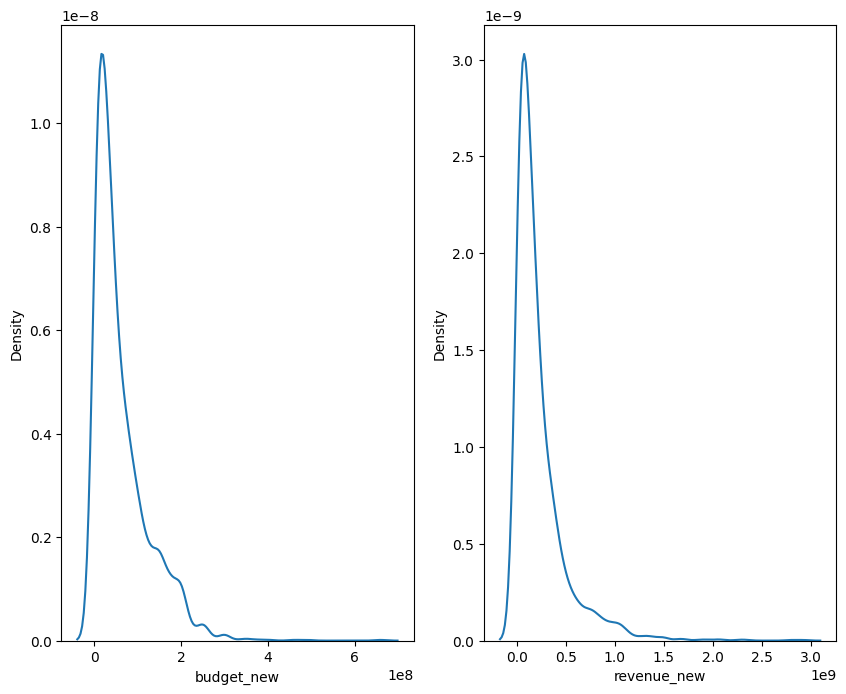

In [1466]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8))
sns.kdeplot(data=movies, x="budget_new", ax=axes[0])
sns.kdeplot(data=movies, x="revenue_new", ax=axes[1])

In [1467]:
movies[["budget_new","revenue_new"]].describe()

,budget_new,revenue_new
count,2.413000e+03,2.401000e+03
mean,6.081643e+07,2.232790e+08
std,6.247818e+07,2.739272e+08
min,7.000000e+03,2.160000e+02
25%,1.500000e+07,5.526216e+07
50%,4.000000e+07,1.363000e+08
75%,8.500000e+07,2.854446e+08
max,6.588000e+08,2.923706e+09


In [1468]:
movies.isna().sum()

movie_id                   0
release_date               0
runtime                    0
budget                     0
revenue                    0
popularity                 0
vote_average               0
vote_count                 0
title_new                  0
original_language_new      0
status_new                 0
overview_new               0
budget_new                90
revenue_new              102
dtype: int64

In [1469]:
movies['budget_new']=movies['budget_new'].fillna(movies['budget_new'].median())
movies['revenue_new']=movies['revenue_new'].fillna(movies['revenue_new'].median())

<Axes: xlabel='revenue_new', ylabel='Density'>

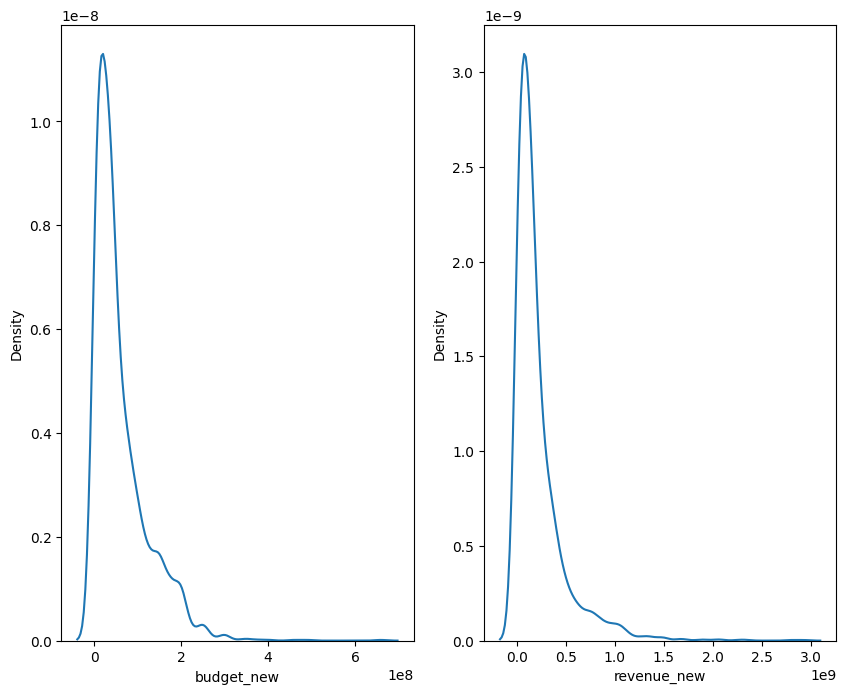

In [1470]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8))
sns.kdeplot(data=movies, x="budget_new", ax=axes[0])
sns.kdeplot(data=movies, x="revenue_new", ax=axes[1])

In [1471]:
movies[["budget_new","revenue_new"]].describe()

,budget_new,revenue_new
count,2.503000e+03,2.503000e+03
mean,6.006794e+07,2.197345e+08
std,6.146653e+07,2.688363e+08
min,7.000000e+03,2.160000e+02
25%,1.620000e+07,5.761571e+07
50%,4.000000e+07,1.363000e+08
75%,8.225000e+07,2.711653e+08
max,6.588000e+08,2.923706e+09


In [1472]:
movies.isna().sum()

movie_id                 0
release_date             0
runtime                  0
budget                   0
revenue                  0
popularity               0
vote_average             0
vote_count               0
title_new                0
original_language_new    0
status_new               0
overview_new             0
budget_new               0
revenue_new              0
dtype: int64

1. Distribution stays the same
2. Imputed with median

## Cleaning movie_keywords dataset

In [1473]:
movie_keywords.sample(7)

,movie_id,keyword_id,keyword_name
26199,371638,818,based on novel or book
39598,1547,9457,single
2770,500,11071,plan gone wrong
37251,1106739,323809,depressing
14874,933260,202550,substance
29316,82633,14707,brutality
5,157336,4565,dystopia


In [1474]:
movie_keywords.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41701 entries, 0 to 41700
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   movie_id      41701 non-null  int64 
 1   keyword_id    41701 non-null  int64 
 2   keyword_name  41701 non-null  object
dtypes: int64(2), object(1)
memory usage: 977.5+ KB


NOTE - No missing entries. Only issue found in keyword_name data type. Should be in string.

Numeric data types are PK and FK which should be checked for orphan movies. If movie_id in this table does not exists in movies data set, then eliminate that record. Movies record should be treated as primary record and Movie records are a bigger subset here because each Movie has crew,cast,genres,keywords etc..

In [1475]:
movie_keywords[(movie_keywords["movie_id"]<=0) | (movie_keywords["keyword_id"]<=0)]

,movie_id,keyword_id,keyword_name


No unexpected entries in the ids col, OK!!

In [1476]:
movie_keywords["keyword_name_new"] = movie_keywords["keyword_name"].str.strip().convert_dtypes(convert_string=True)

In [1477]:
movie_keywords[~(movie_keywords["keyword_name"] == movie_keywords["keyword_name_new"])].shape

(34, 4)

It seems like there were few rows where keywords had trailing/leading white spaces or escape sequences.

Below are all those records.

In [1478]:
diff = movie_keywords.loc[
    movie_keywords["keyword_name"] != movie_keywords["keyword_name_new"],["keyword_name", "keyword_name_new"]]

diff.to_string()

for old, new in diff.itertuples(index=False, name=None):
    print("Original:", repr(old))
    print("Cleaned: ", repr(new))
    print("-" * 30)

Original: 'simulated reality '
Cleaned:  'simulated reality'
------------------------------
Original: 'simulated reality '
Cleaned:  'simulated reality'
------------------------------
Original: 'political intrigue\xa0'
Cleaned:  'political intrigue'
------------------------------
Original: 'bellhop \xa0'
Cleaned:  'bellhop'
------------------------------
Original: 'cops and robbers\xa0'
Cleaned:  'cops and robbers'
------------------------------
Original: 'political intrigue\xa0'
Cleaned:  'political intrigue'
------------------------------
Original: 'political intrigue\xa0'
Cleaned:  'political intrigue'
------------------------------
Original: 'brother sister\xa0'
Cleaned:  'brother sister'
------------------------------
Original: 'lighthouse keeper   '
Cleaned:  'lighthouse keeper'
------------------------------
Original: 'family business '
Cleaned:  'family business'
------------------------------
Original: 'time freeze\xa0'
Cleaned:  'time freeze'
------------------------------
Or

There are differences b/w new stripped keywords and original keyword column. But the difference is justified. Either there were extra spaces or some escape sequences, OK!!

In [1479]:
movie_keywords.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41701 entries, 0 to 41700
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   movie_id          41701 non-null  int64 
 1   keyword_id        41701 non-null  int64 
 2   keyword_name      41701 non-null  object
 3   keyword_name_new  41701 non-null  string
dtypes: int64(2), object(1), string(1)
memory usage: 1.3+ MB


In [1480]:
movie_keywords=movie_keywords.drop(["keyword_name"],axis=1)

In [1481]:
movie_keywords.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41701 entries, 0 to 41700
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   movie_id          41701 non-null  int64 
 1   keyword_id        41701 non-null  int64 
 2   keyword_name_new  41701 non-null  string
dtypes: int64(2), string(1)
memory usage: 977.5 KB


Number of records before and after conversion remains same.

In [1482]:
movie_keywords[~(movie_keywords["movie_id"].isin(movies["movie_id"]))]

,movie_id,keyword_id,keyword_name_new


No existence of orphan rows.OKK!

In [1483]:
movie_keywords.duplicated(subset=["movie_id", "keyword_id"]).sum()

np.int64(20)

As the Ids indicates FK and PK, we must only use these 2 cols for duplication check and removal

In [1484]:
movie_keywords[movie_keywords.duplicated(subset=["movie_id", "keyword_id"],keep=False)].sort_values(["movie_id", "keyword_id"])

,movie_id,keyword_id,keyword_name_new
4285,111,701,cuba
41698,111,701,cuba
28217,947,210434,thoughtful
41690,947,210434,thoughtful
14844,948,2546,mask
41692,948,2546,mask
3211,1271,329753,epic heroes
41696,1271,329753,epic heroes
12570,1368,6149,police
41684,1368,6149,police


Duplicate rows identified

In [1485]:
movie_keywords.drop_duplicates(subset=["movie_id", "keyword_id"],inplace=True)

Deleted duplicates

In [1486]:
movie_keywords.duplicated(subset=["movie_id", "keyword_id"]).sum()

np.int64(0)

In [1487]:
movie_keywords.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41681 entries, 0 to 41680
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   movie_id          41681 non-null  int64 
 1   keyword_id        41681 non-null  int64 
 2   keyword_name_new  41681 non-null  string
dtypes: int64(2), string(1)
memory usage: 1.3 MB


41701 - 20 = 41,681, OK!!

## Cleaning Movie Genres dataset

In [1488]:
movie_genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6888 entries, 0 to 6887
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  6888 non-null   int64
 1   genre_id  6888 non-null   int64
dtypes: int64(2)
memory usage: 107.8 KB


No null values observed. 

In [1489]:
movie_genres[(movie_genres["movie_id"]<=0) | (movie_genres["genre_id"]<=0)]

,movie_id,genre_id


In [1490]:
movie_genres[movie_genres.duplicated()].shape

(10, 2)

In [1491]:
movie_genres[movie_genres.duplicated(keep=False)].sort_values(["movie_id", "genre_id"])

,movie_id,genre_id
3257,90,28
6881,90,28
5937,1429,80
6885,1429,80
5787,8914,28
6884,8914,28
4607,9334,14
6882,9334,14
5345,9477,12
6879,9477,12


All duplicated records make no sense, since combination of movie_id and genre_id is a unique indentifier and each combination will identify a single genre for a movie, we will simply remove duplicates

In [1492]:
movie_genres.drop_duplicates(inplace=True)

In [1493]:
movie_genres[movie_genres.duplicated()].shape

(0, 2)

In [1494]:
movie_genres[~(movie_genres["movie_id"].isin(movies["movie_id"]))]

,movie_id,genre_id


No orphan records, OK!!

In [1495]:
movie_genres.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6878 entries, 0 to 6877
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  6878 non-null   int64
 1   genre_id  6878 non-null   int64
dtypes: int64(2)
memory usage: 161.2 KB


## Cleaning Movie Genres dataset

In [1496]:
genres.sample(6)

,genre_id,genre_name
13,10749,Romance
0,28,Action
17,10752,War
14,878,Science Fiction
18,37,Western
16,53,Thriller


In [1497]:
genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   genre_id    19 non-null     int64 
 1   genre_name  19 non-null     object
dtypes: int64(1), object(1)
memory usage: 436.0+ bytes


No null entries, OK!!

In [1498]:
genres[(genres["genre_id"]<=0)]

,genre_id,genre_name


No unexpected IDs, OK!!

In [1499]:
genres[~(genres["genre_id"].isin(movie_genres["genre_id"]))]

,genre_id,genre_name


No orphan rows

In [1500]:
genres["genres_name_new"] = genres["genre_name"].str.strip().convert_dtypes(convert_string=True)

In [1501]:
genres[~(genres["genres_name_new"] ==  genres["genre_name"])]

,genre_id,genre_name,genres_name_new


In [1502]:
genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   genre_id         19 non-null     int64 
 1   genre_name       19 non-null     object
 2   genres_name_new  19 non-null     string
dtypes: int64(1), object(1), string(1)
memory usage: 588.0+ bytes


In [1503]:
genres=genres.drop(["genre_name"],axis=1)

In [1504]:
genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   genre_id         19 non-null     int64 
 1   genres_name_new  19 non-null     string
dtypes: int64(1), string(1)
memory usage: 436.0 bytes


In [1505]:
genres[genres.duplicated()]

,genre_id,genres_name_new


No duplicates, OK!!

## Cleaning Crew dataset

In [1506]:
crew.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7297 entries, 0 to 7296
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   crew_row_id  7297 non-null   int64 
 1   movie_id     7297 non-null   int64 
 2   person_id    7297 non-null   int64 
 3   person_name  7297 non-null   object
 4   job          7297 non-null   object
 5   department   7297 non-null   object
dtypes: int64(3), object(3)
memory usage: 342.2+ KB


No null rows. OK!!

Person_name,job,dept has object dtype

In [1507]:
crew.sample(6)

,crew_row_id,movie_id,person_id,person_name,job,department
2739,2740,308266,57130,Todd Phillips,Writer,Writing
42,43,68718,138,Quentin Tarantino,Director,Directing
3492,3493,91586,2128,Leigh Whannell,Screenplay,Writing
5512,5513,7484,31025,Nat Mauldin,Screenplay,Writing
2734,2735,353491,1012,Anders Thomas Jensen,Screenplay,Writing
625,626,103,1032,Martin Scorsese,Director,Directing


In [1508]:
crew[(crew["crew_row_id"]<=0) | (crew["movie_id"]<=0) | (crew["person_id"]<=0)]

,crew_row_id,movie_id,person_id,person_name,job,department


No unexpected IDs, OK!!

In [1509]:
crew[~(crew["movie_id"].isin(movies["movie_id"]))]

,crew_row_id,movie_id,person_id,person_name,job,department


No orphan rows for movies, OKK!

In [1510]:
crew[crew.duplicated(subset=["crew_row_id","movie_id","person_id"])].shape

(8, 6)

In [1511]:
crew[crew.duplicated(subset=["crew_row_id","movie_id","person_id"],keep=False)].sort_values(by=["crew_row_id","movie_id","person_id"])

,crew_row_id,movie_id,person_id,person_name,job,department
263,264,808,12083,Joe Stillman,Writer,Writing
7296,264,808,12083,Joe Stillman,Writer,Writing
748,749,1858,15345,Alex Kurtzman,Screenplay,Writing
7290,749,1858,15345,Alex Kurtzman,Screenplay,Writing
1025,1026,566525,57264,David Callaham,Screenplay,Writing
7292,1026,566525,57264,David Callaham,Screenplay,Writing
1055,1056,950,5714,Carlos Saldanha,Director,Directing
7289,1056,950,5714,Carlos Saldanha,Director,Directing
1242,1243,76492,53684,Robert Smigel,Screenplay,Writing
7293,1243,76492,53684,Robert Smigel,Screenplay,Writing


Exact same values duplicated, and makes no sense at all, Will remove

In [1512]:
crew.drop_duplicates(inplace=True)

In [1513]:
crew[crew.duplicated(subset=["crew_row_id","movie_id","person_id"],keep=False)].sort_values(by=["crew_row_id","movie_id","person_id"])

,crew_row_id,movie_id,person_id,person_name,job,department


In [1514]:
crew.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7289 entries, 0 to 7288
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   crew_row_id  7289 non-null   int64 
 1   movie_id     7289 non-null   int64 
 2   person_id    7289 non-null   int64 
 3   person_name  7289 non-null   object
 4   job          7289 non-null   object
 5   department   7289 non-null   object
dtypes: int64(3), object(3)
memory usage: 398.6+ KB


Converting object dtypes to string and verifying that no unexpected error happens

In [1515]:
crew["person_name_new"] = crew["person_name"].str.strip().convert_dtypes(convert_string=True)

In [1516]:
crew["job_new"] = crew["job"].str.strip().convert_dtypes(convert_string=True)

In [1517]:
crew["department_new"] = crew["department"].str.strip().convert_dtypes(convert_string=True)

All featues with object dtypes converted to string. Old records match with existing records.

In [1518]:
obj_cols = crew.select_dtypes("object").columns
for x in obj_cols:
    print(crew[~(crew[f"{x}_new"] == crew[f"{x}"])])

Empty DataFrame
Columns: [crew_row_id, movie_id, person_id, person_name, job, department, person_name_new, job_new, department_new]
Index: []
Empty DataFrame
Columns: [crew_row_id, movie_id, person_id, person_name, job, department, person_name_new, job_new, department_new]
Index: []
Empty DataFrame
Columns: [crew_row_id, movie_id, person_id, person_name, job, department, person_name_new, job_new, department_new]
Index: []


In [1519]:
crew.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7289 entries, 0 to 7288
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   crew_row_id      7289 non-null   int64 
 1   movie_id         7289 non-null   int64 
 2   person_id        7289 non-null   int64 
 3   person_name      7289 non-null   object
 4   job              7289 non-null   object
 5   department       7289 non-null   object
 6   person_name_new  7289 non-null   string
 7   job_new          7289 non-null   string
 8   department_new   7289 non-null   string
dtypes: int64(3), object(3), string(3)
memory usage: 569.5+ KB


## Cleaning Cast dataset

In [1520]:
cast.sample(6)

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order
19823,19824,9360,177100,Vincent Castellanos,Mateo,7
14863,14864,582014,86310,Connie Britton,Dean Walker,8
464,465,634649,15277,Jon Favreau,Happy Hogan,4
12983,12984,460019,1560379,Hayden Szeto,Brad Chang,4
1195,1196,339403,19498,Jon Bernthal,Griff,5
7581,7582,1573,6573,William Sadler,Stuart,2


In [1521]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24917 entries, 0 to 24916
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   cast_row_id     24917 non-null  int64 
 1   movie_id        24917 non-null  int64 
 2   person_id       24917 non-null  int64 
 3   actor_name      24917 non-null  object
 4   character_name  24906 non-null  object
 5   cast_order      24917 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 1.1+ MB


NOTE-Character name has some null values. Handled at last

It seems like the person_id is unique to this table and does not have any relation to other table specially like CREW. Generally, we also have seperation b/w cast and crew. Cast is like on camera and crew is off camera.

And cast_row_id is like PK for the cast data set. 

So, only contender for orphan check is movie_id

In [1522]:
cast[~(cast["movie_id"].isin(movies["movie_id"]))]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order


In [1523]:
cast[(cast["cast_row_id"]<=0) | (cast["movie_id"]<=0) | (cast["person_id"]<=0)]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order


No Unexpected IDs, OK!!

In [1524]:
cast["character_name_new"] = cast["character_name"].str.strip().convert_dtypes(convert_string=True)
cast["actor_name_new"] = cast["actor_name"].str.strip().convert_dtypes(convert_string=True)

In [1525]:
obj_cols = cast.select_dtypes("object").columns
for x in obj_cols:
    print(cast[~(cast[f"{x}_new"] == cast[f"{x}"])])

Empty DataFrame
Columns: [cast_row_id, movie_id, person_id, actor_name, character_name, cast_order, character_name_new, actor_name_new]
Index: []
Empty DataFrame
Columns: [cast_row_id, movie_id, person_id, actor_name, character_name, cast_order, character_name_new, actor_name_new]
Index: []


Object Feature converted to string as expected. The empty character value remains here.

In [1526]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24917 entries, 0 to 24916
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   cast_row_id         24917 non-null  int64 
 1   movie_id            24917 non-null  int64 
 2   person_id           24917 non-null  int64 
 3   actor_name          24917 non-null  object
 4   character_name      24906 non-null  object
 5   cast_order          24917 non-null  int64 
 6   character_name_new  24906 non-null  string
 7   actor_name_new      24917 non-null  string
dtypes: int64(4), object(2), string(2)
memory usage: 1.5+ MB


Duplicates handling

In [1527]:
cast[cast.duplicated(subset=["cast_row_id","movie_id","person_id"])].shape

(15, 8)

In [1528]:
cast[cast.duplicated(subset=["cast_row_id","movie_id","person_id"],keep=False)].sort_values(by=["cast_row_id","movie_id","person_id"])

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
516,517,105,1067,Marc McClure,Dave McFly,6,Dave McFly,Marc McClure
24916,517,105,1067,Marc McClure,Dave McFly,6,Dave McFly,Marc McClure
1336,1337,1422,6193,Leonardo DiCaprio,Billy,0,Billy,Leonardo DiCaprio
24907,1337,1422,6193,Leonardo DiCaprio,Billy,0,Billy,Leonardo DiCaprio
3296,3297,337339,17647,Michelle Rodriguez,Letty Ortiz,3,Letty Ortiz,Michelle Rodriguez
24910,3297,337339,17647,Michelle Rodriguez,Letty Ortiz,3,Letty Ortiz,Michelle Rodriguez
4534,4535,8392,55664,Chika Sakamoto,Mei Kusakabe (voice),1,Mei Kusakabe (voice),Chika Sakamoto
24903,4535,8392,55664,Chika Sakamoto,Mei Kusakabe (voice),1,Mei Kusakabe (voice),Chika Sakamoto
5598,5599,1734,18918,Dwayne Johnson,Mathayus / The Scorpion King,7,Mathayus / The Scorpion King,Dwayne Johnson
24904,5599,1734,18918,Dwayne Johnson,Mathayus / The Scorpion King,7,Mathayus / The Scorpion King,Dwayne Johnson


In [1529]:
cast.drop_duplicates(subset=["cast_row_id","movie_id","person_id"],inplace=True)

In [1530]:
cast[cast.duplicated(subset=["cast_row_id","movie_id","person_id"],keep=False)].sort_values(by=["cast_row_id","movie_id","person_id"])

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new


In [1531]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24902 entries, 0 to 24901
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   cast_row_id         24902 non-null  int64 
 1   movie_id            24902 non-null  int64 
 2   person_id           24902 non-null  int64 
 3   actor_name          24902 non-null  object
 4   character_name      24891 non-null  object
 5   cast_order          24902 non-null  int64 
 6   character_name_new  24891 non-null  string
 7   actor_name_new      24902 non-null  string
dtypes: int64(4), object(2), string(2)
memory usage: 1.7+ MB


Null handling

In [1532]:
cast["character_name"].isnull().sum()

np.int64(11)

In [1533]:
cast[cast["character_name"].isnull()]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
14465,14466,97370,1245,Scarlett Johansson,NaN,0,<NA>,Scarlett Johansson
14466,14467,97370,1047644,Jeremy McWilliams,NaN,1,<NA>,Jeremy McWilliams
14467,14468,97370,1711557,Lynsey Taylor Mackay,NaN,2,<NA>,Lynsey Taylor Mackay
14468,14469,97370,1711559,Dougie McConnell,NaN,3,<NA>,Dougie McConnell
14469,14470,97370,1711561,Kevin McAlinden,NaN,4,<NA>,Kevin McAlinden
14470,14471,97370,1711616,D. Meade,NaN,5,<NA>,D. Meade
14471,14472,97370,74841,Andrew Gorman,NaN,6,<NA>,Andrew Gorman
14472,14473,97370,1711626,Joe Szula,NaN,7,<NA>,Joe Szula
14473,14474,97370,136796,Kryštof Hádek,NaN,8,<NA>,Kryštof Hádek
14474,14475,97370,1711628,Roy Armstrong,NaN,9,<NA>,Roy Armstrong


We can also fill blank character_name based on IMDB - https://www.imdb.com/title/tt1441395/fullcredits/ - Movie is "Under the Skin" FOR id - 97370.

For movie_ID = 5156, Bicycle Thieves, I was not able to find the name of character so deleting that row.

In [1534]:
cast[(cast["character_name"].isnull()) & (cast["movie_id"] == 97370)]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
14465,14466,97370,1245,Scarlett Johansson,NaN,0,<NA>,Scarlett Johansson
14466,14467,97370,1047644,Jeremy McWilliams,NaN,1,<NA>,Jeremy McWilliams
14467,14468,97370,1711557,Lynsey Taylor Mackay,NaN,2,<NA>,Lynsey Taylor Mackay
14468,14469,97370,1711559,Dougie McConnell,NaN,3,<NA>,Dougie McConnell
14469,14470,97370,1711561,Kevin McAlinden,NaN,4,<NA>,Kevin McAlinden
14470,14471,97370,1711616,D. Meade,NaN,5,<NA>,D. Meade
14471,14472,97370,74841,Andrew Gorman,NaN,6,<NA>,Andrew Gorman
14472,14473,97370,1711626,Joe Szula,NaN,7,<NA>,Joe Szula
14473,14474,97370,136796,Kryštof Hádek,NaN,8,<NA>,Kryštof Hádek
14474,14475,97370,1711628,Roy Armstrong,NaN,9,<NA>,Roy Armstrong


In [1535]:
character_mapping = {
    "Scarlett Johansson": "The Female",
    "Jeremy McWilliams": "The Bad Man",
    "Lynsey Taylor Mackay": "The Dead Woman",
    "Dougie McConnell": "Pick-Up Man",
    "Kevin McAlinden": "First Victim",
    "D. Meade": "Leering Man",
    "Andrew Gorman": "Second Victim",
    "Joe Szula": "Man at Club",
    "Kryštof Hádek": "The Swimmer (as Krystof Hadek)",
    "Roy Armstrong": "Father at Beach"
}

mask = cast["movie_id"] == 97370

cast.loc[mask, "character_name_new"] = (cast.loc[mask, "actor_name"].map(character_mapping))

In [1536]:
cast[(cast["character_name"].isnull()) & (cast["movie_id"] == 97370)]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
14465,14466,97370,1245,Scarlett Johansson,NaN,0,The Female,Scarlett Johansson
14466,14467,97370,1047644,Jeremy McWilliams,NaN,1,The Bad Man,Jeremy McWilliams
14467,14468,97370,1711557,Lynsey Taylor Mackay,NaN,2,The Dead Woman,Lynsey Taylor Mackay
14468,14469,97370,1711559,Dougie McConnell,NaN,3,Pick-Up Man,Dougie McConnell
14469,14470,97370,1711561,Kevin McAlinden,NaN,4,First Victim,Kevin McAlinden
14470,14471,97370,1711616,D. Meade,NaN,5,Leering Man,D. Meade
14471,14472,97370,74841,Andrew Gorman,NaN,6,Second Victim,Andrew Gorman
14472,14473,97370,1711626,Joe Szula,NaN,7,Man at Club,Joe Szula
14473,14474,97370,136796,Kryštof Hádek,NaN,8,The Swimmer (as Krystof Hadek),Kryštof Hádek
14474,14475,97370,1711628,Roy Armstrong,NaN,9,Father at Beach,Roy Armstrong


In [1537]:
cast[cast["character_name"].isnull()]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
14465,14466,97370,1245,Scarlett Johansson,NaN,0,The Female,Scarlett Johansson
14466,14467,97370,1047644,Jeremy McWilliams,NaN,1,The Bad Man,Jeremy McWilliams
14467,14468,97370,1711557,Lynsey Taylor Mackay,NaN,2,The Dead Woman,Lynsey Taylor Mackay
14468,14469,97370,1711559,Dougie McConnell,NaN,3,Pick-Up Man,Dougie McConnell
14469,14470,97370,1711561,Kevin McAlinden,NaN,4,First Victim,Kevin McAlinden
14470,14471,97370,1711616,D. Meade,NaN,5,Leering Man,D. Meade
14471,14472,97370,74841,Andrew Gorman,NaN,6,Second Victim,Andrew Gorman
14472,14473,97370,1711626,Joe Szula,NaN,7,Man at Club,Joe Szula
14473,14474,97370,136796,Kryštof Hádek,NaN,8,The Swimmer (as Krystof Hadek),Kryštof Hádek
14474,14475,97370,1711628,Roy Armstrong,NaN,9,Father at Beach,Roy Armstrong


In [1538]:
cast.drop(cast[cast["person_id"] == 1077250].index, inplace=True)

In [1539]:
cast[cast["character_name"].isnull()]

,cast_row_id,movie_id,person_id,actor_name,character_name,cast_order,character_name_new,actor_name_new
14465,14466,97370,1245,Scarlett Johansson,NaN,0,The Female,Scarlett Johansson
14466,14467,97370,1047644,Jeremy McWilliams,NaN,1,The Bad Man,Jeremy McWilliams
14467,14468,97370,1711557,Lynsey Taylor Mackay,NaN,2,The Dead Woman,Lynsey Taylor Mackay
14468,14469,97370,1711559,Dougie McConnell,NaN,3,Pick-Up Man,Dougie McConnell
14469,14470,97370,1711561,Kevin McAlinden,NaN,4,First Victim,Kevin McAlinden
14470,14471,97370,1711616,D. Meade,NaN,5,Leering Man,D. Meade
14471,14472,97370,74841,Andrew Gorman,NaN,6,Second Victim,Andrew Gorman
14472,14473,97370,1711626,Joe Szula,NaN,7,Man at Club,Joe Szula
14473,14474,97370,136796,Kryštof Hádek,NaN,8,The Swimmer (as Krystof Hadek),Kryštof Hádek
14474,14475,97370,1711628,Roy Armstrong,NaN,9,Father at Beach,Roy Armstrong


In [1540]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24901 entries, 0 to 24901
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   cast_row_id         24901 non-null  int64 
 1   movie_id            24901 non-null  int64 
 2   person_id           24901 non-null  int64 
 3   actor_name          24901 non-null  object
 4   character_name      24891 non-null  object
 5   cast_order          24901 non-null  int64 
 6   character_name_new  24901 non-null  string
 7   actor_name_new      24901 non-null  string
dtypes: int64(4), object(2), string(2)
memory usage: 1.7+ MB


15 duplicates, 1 blank = 16, Original = 24917, 24917-16 = 24901 (expected), OK!!

In [1541]:
cast=cast.drop(["actor_name","character_name"],axis=1)

In [1542]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24901 entries, 0 to 24901
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   cast_row_id         24901 non-null  int64 
 1   movie_id            24901 non-null  int64 
 2   person_id           24901 non-null  int64 
 3   cast_order          24901 non-null  int64 
 4   character_name_new  24901 non-null  string
 5   actor_name_new      24901 non-null  string
dtypes: int64(4), string(2)
memory usage: 1.3 MB


Loading data in MY SQL DB

In [1543]:
from sqlalchemy import create_engine,text

In [1544]:
password = "dbms%40123"
#https://stackoverflow.com/questions/1423804/writing-a-connection-string-when-password-contains-special-characters

host = "127.0.0.1"
engine = create_engine(
    f"mysql+pymysql://root:{password}@{host}:3306/"
    #mysql+pymysql://<username>:<password>@<host>/<dbname>[?<options>]
)

connection = engine.connect()

In [1545]:
query = text("""

CREATE DATABASE IF NOT EXISTS Movie_Analytis;

""")

with engine.begin() as connection:
    result = connection.execute(query)

engine = create_engine(
    f"mysql+pymysql://root:{password}@{host}:3306/Movie_Analytis"
    #mysql+pymysql://<username>:<password>@<host>/<dbname>[?<options>]
)

connection = engine.connect()

In [1546]:
#T1 - Movies

create_query_1 = text("""
CREATE TABLE IF NOT EXISTS Movies
(
	Movie_ID INT PRIMARY KEY,
    Title VARCHAR(255),
    Original_Language VARCHAR(10),
    Release_Date DATE,
    Runtime INT,
    Budget double,
    Revenue Double,
    Popularity FLOAT,
    Vote_Average float,
    Vote_Count INT,
    Status VARCHAR(50),
    Overview TEXT
);
""")

with engine.begin() as connection:
    result = connection.execute(create_query_1)

#T2 - Genres

create_query_2 = text("""
CREATE TABLE IF NOT EXISTS Genres
(
	Genre_ID INT PRIMARY KEY,
    Genres_name VARCHAR(50)
);
""")

with engine.begin() as connection:
    result = connection.execute(create_query_2)

#T3 - Movie_Genres

create_query_3 = text("""
CREATE TABLE IF NOT EXISTS Movie_Genres
(
	Movie_ID INT,
    Genre_ID INT,
    FOREIGN KEY (Movie_ID) REFERENCES Movies(Movie_ID),
    FOREIGN KEY (Genre_ID) REFERENCES Genres(Genre_ID)
);""")

with engine.begin() as connection:
    result = connection.execute(create_query_3)

#T4-Cast

create_query_4 = text("""
CREATE TABLE IF NOT EXISTS Cast
(
	Cast_Row_ID INT auto_increment PRIMARY KEY,
    Movie_ID INT,
    Person_ID INT,
    Actor_Name VARCHAR(255),
    Character_Name VARCHAR(400),
    Cast_Order INT,
    FOREIGN KEY (Movie_ID) references Movies(Movie_ID)
);
""")

with engine.begin() as connection:
    result = connection.execute(create_query_4)

#Table - 5

create_query_5 = text("""
CREATE TABLE IF NOT EXISTS Crew
(
	Crew_Row_ID INT auto_increment PRIMARY KEY,
    Movie_ID INT,
    Person_ID INT,
    Person_Name VARCHAR(255),
    Job VARCHAR(255),
    Department VARCHAR(100),
    FOREIGN KEY (Movie_ID) references Movies(Movie_ID)
);
""")

with engine.begin() as connection:
    result = connection.execute(create_query_5)

#T6- Movie_Keywords

create_query_6 = text("""
CREATE TABLE IF NOT EXISTS Movie_Keywords
(
	Movie_ID INT,
	Keyword_ID INT,
    Keyword_Name VARCHAR(100),
    FOREIGN KEY (Movie_ID) references Movies(Movie_ID)
);
""")

with engine.begin() as connection:
    result = connection.execute(create_query_6)

movies = pd.read_csv("dataset/movies.csv")
movie_keywords = pd.read_csv("dataset/movie_keywords.csv")
movie_genres = pd.read_csv("dataset/movie_genres.csv")
cast = pd.read_csv("dataset/cast.csv")
crew = pd.read_csv("dataset/crew.csv")
genres = pd.read_csv("dataset/genres.csv")

In [1547]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2503 entries, 0 to 2508
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   movie_id               2503 non-null   int64         
 1   release_date           2503 non-null   datetime64[ns]
 2   runtime                2503 non-null   int64         
 3   budget                 2503 non-null   float64       
 4   revenue                2503 non-null   float64       
 5   popularity             2503 non-null   float64       
 6   vote_average           2503 non-null   float64       
 7   vote_count             2503 non-null   int64         
 8   title_new              2503 non-null   string        
 9   original_language_new  2503 non-null   string        
 10  status_new             2503 non-null   string        
 11  overview_new           2503 non-null   string        
 12  budget_new             2503 non-null   float64       
 13  revenue_

In [1548]:
movies=movies.drop(["revenue","budget"],axis=1)
movies=movies.rename(columns={
    "original_language_new": "original_language",
    "revenue_new": "revenue",
    "status_new":"status",
    "overview_new":"overview",
    "budget_new":"budget",
    "title_new":"title"
})

In [1549]:
genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   genre_id         19 non-null     int64 
 1   genres_name_new  19 non-null     string
dtypes: int64(1), string(1)
memory usage: 436.0 bytes


In [1550]:
genres=genres.rename(columns={
    "genres_name_new":"genres_name"
})

In [1551]:
movie_genres.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6878 entries, 0 to 6877
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  6878 non-null   int64
 1   genre_id  6878 non-null   int64
dtypes: int64(2)
memory usage: 161.2 KB


In [1552]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24901 entries, 0 to 24901
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   cast_row_id         24901 non-null  int64 
 1   movie_id            24901 non-null  int64 
 2   person_id           24901 non-null  int64 
 3   cast_order          24901 non-null  int64 
 4   character_name_new  24901 non-null  string
 5   actor_name_new      24901 non-null  string
dtypes: int64(4), string(2)
memory usage: 1.3 MB


In [1553]:
cast=cast.rename(columns={
    "character_name_new":"character_name",
    "actor_name_new":"actor_name"
})

In [1554]:
crew.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7289 entries, 0 to 7288
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   crew_row_id      7289 non-null   int64 
 1   movie_id         7289 non-null   int64 
 2   person_id        7289 non-null   int64 
 3   person_name      7289 non-null   object
 4   job              7289 non-null   object
 5   department       7289 non-null   object
 6   person_name_new  7289 non-null   string
 7   job_new          7289 non-null   string
 8   department_new   7289 non-null   string
dtypes: int64(3), object(3), string(3)
memory usage: 569.5+ KB


In [1555]:
crew = crew.drop(["person_name","job","department"],axis=1)
crew=crew.rename(columns={
    "person_name_new":"person_name",
    "job_new":"job",
    "department_new":"department"
})

In [1556]:
movie_keywords.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41681 entries, 0 to 41680
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   movie_id          41681 non-null  int64 
 1   keyword_id        41681 non-null  int64 
 2   keyword_name_new  41681 non-null  string
dtypes: int64(2), string(1)
memory usage: 1.3 MB


In [1557]:
movie_keywords=movie_keywords.rename(columns={
    "keyword_name_new":"keyword_name",
})

In [1558]:
if "DATA_INSERTED" not in globals():
    with engine.begin() as connection:
        movies.to_sql(
            "Movies",
            con=connection,
            if_exists="append",
            index=False
        )
        genres.to_sql(
            "Genres",
            con=connection,
            if_exists="append",
            index=False
        )
        movie_genres.to_sql(
            "Movie_Genres",
            con=connection,
            if_exists="append",
            index=False
        )
        cast.to_sql(
            "Cast",
            con=connection,
            if_exists="append",
            index=False        
        )
        crew.to_sql(
            "Crew",
            con=connection,
            if_exists="append",
            index=False        
        )
        movie_keywords.to_sql(
            "Movie_Keywords",
            con=connection,
            if_exists="append",
            index=False        
        )
        DATA_INSERTED = True

C:\Users\nand4\AppData\Local\Temp\ipykernel_20680\2203529411.py:3: UserWarning: The provided table name 'Movies' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  movies.to_sql(
C:\Users\nand4\AppData\Local\Temp\ipykernel_20680\2203529411.py:9: UserWarning: The provided table name 'Genres' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  genres.to_sql(
C:\Users\nand4\AppData\Local\Temp\ipykernel_20680\2203529411.py:15: UserWarning: The provided table name 'Movie_Genres' is not found exactly as such in the database after writing the table, possibly due to case sensitivity issues. Consider using lower case table names.
  movie_genres.to_sql(
C:\Users\nand4\AppData\Local\Temp\ipykernel_20680\2203529411.py:21: UserWarning: The provided table name 'Cast' is not found exactly as such in the

In [1562]:
tables = [
    ("movies", movies),
    ("movie_keywords", movie_keywords),
    ("movie_genres", movie_genres),
    ("cast", cast),
    ("crew", crew),
    ("genres", genres)
]

In [1564]:
with engine.begin() as connection:
    for table_name, df in tables:
        count = connection.execute(text(f"SELECT COUNT(*) FROM {table_name}")).scalar()
        if count == df.shape[0]:
            print(f"{table_name} - success")
        else:
            print(f"{table_name} - mismatch "f"(db={count}, df={df.shape[0]})")


movies - success
movie_keywords - success
movie_genres - success
cast - success
crew - success
genres - success
